# 15 · Numenta Anomaly Benchmark (NAB) – evaluating our detector

**Utility for the City Brain: medium** · Domain: generic time series · Incident types: evaluation of all

> 58 real and artificial time series with labelled anomaly windows. We run the spec's detection rule on them to see how often it catches anomalies and how often it raises false alarms.

| | |
|---|---|
| **Source** | GitHub `numenta/NAB` (Ahmad et al. 2017, *Neurocomputing*) |
| **Licence** | MIT (licence file included) |
| **In this repo** | Sample: `realTraffic`, `realKnownCause`, `artificialNoAnomaly` series + `labels/combined_windows.json` |
| **Get it** | `git clone https://github.com/numenta/NAB` |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

Each series is a CSV with `timestamp, value`. `combined_windows.json` maps each file to a list of `[start, end]` **anomaly windows** (labelled by humans or by the known cause). `realTraffic` = road speed / occupancy / travel time from Minnesota; `artificialNoAnomaly` = clean signals with nothing to find.

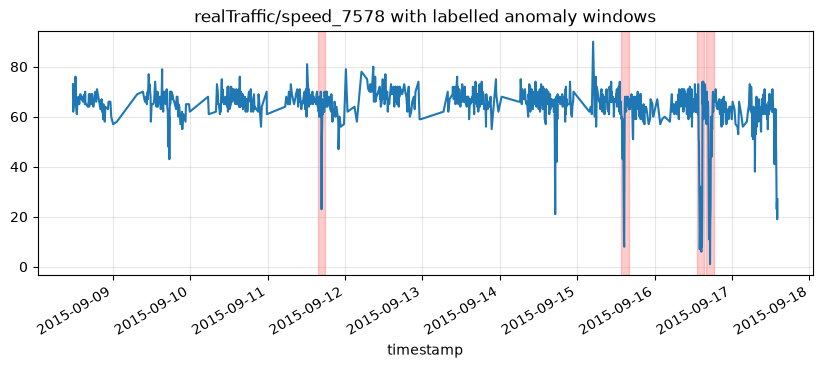

In [2]:
ROOT = Path(path('anomaly-benchmark/nab/data'))
win = json.load(open(path('anomaly-benchmark/nab/labels/combined_windows.json')))
s = pd.read_csv(ROOT / 'realTraffic/speed_7578.csv', parse_dates=['timestamp'])
ax = s.plot(x='timestamp', y='value', title='realTraffic/speed_7578 with labelled anomaly windows', legend=False)
for a_, b_ in win['realTraffic/speed_7578.csv']: ax.axvspan(pd.Timestamp(a_), pd.Timestamp(b_), color='r', alpha=.2)
plt.show()

## 2. The spec rule

Spec (`team-docs/02-graph.md`): running mean with **EMA α = 0.05**, abnormal when |x − μ| > **3σ**, for **3 readings in a row**.

In [3]:
def spec_rule(v, alpha=.05, k=3, n=3, warmup=50):
    # EMA mean / variance; alarm when 3 readings in a row are > 3 sigma away.
    # Abnormal readings don't update the baseline (unless they persist: then they become the new normal).
    mu, var, run, alarms = v[0], (0.05 * abs(v[0]) + 1e-6) ** 2, 0, np.zeros(len(v), bool)
    for i, x in enumerate(v[1:], 1):
        far = abs(x - mu) > k * max(var ** .5, 1e-9)
        run = run + 1 if far else 0
        alarms[i] = run == n and i > warmup                     # one alarm per episode
        if not far or run > 3 * n:
            d = x - mu; mu += alpha * d; var = (1 - alpha) * (var + alpha * d * d)
    return alarms

def evaluate(rel):
    x = pd.read_csv(ROOT / rel, parse_dates=['timestamp'])
    a = spec_rule(x.value.to_numpy(float))
    starts = x.timestamp[a]                                   # alarm episodes
    w = [(pd.Timestamp(p), pd.Timestamp(q)) for p, q in win.get(rel, [])]
    hit = sum(any((t >= p) & (t <= q) for t in starts) for p, q in w)
    false = sum(not any(p <= t <= q for p, q in w) for t in starts)
    days = (x.timestamp.iloc[-1] - x.timestamp.iloc[0]) / pd.Timedelta('1D')
    return len(w), hit, false, days

res = []
for cat in ['realTraffic', 'realKnownCause', 'artificialNoAnomaly']:
    for f in sorted((ROOT / cat).glob('*.csv')):
        n, hit, false, days = evaluate(f'{cat}/{f.name}'); res.append((cat, f.name, n, hit, false, days))
r = pd.DataFrame(res, columns=['category', 'file', 'windows', 'caught', 'false alarms', 'days'])
r['false alarms/day'] = r['false alarms'] / r['days']
summary = r.groupby('category')[['windows', 'caught', 'false alarms', 'days']].sum()
summary['recall'] = (summary.caught / summary.windows).round(2)
summary['false alarms/day'] = (summary['false alarms'] / summary.days).round(2); summary.drop(columns='days')

,windows,caught,false alarms,recall,false alarms/day
category,,,,,
artificialNoAnomaly,0,0,85,NaN,1.21
realKnownCause,19,10,855,0.53,1.16
realTraffic,14,10,48,0.71,0.25


In [4]:
r[r.category == 'artificialNoAnomaly'][['file', 'false alarms', 'false alarms/day']].round(2)

,file,false alarms,false alarms/day
14,art_daily_no_noise.csv,28,2.00
15,art_daily_perfect_square_wave.csv,28,2.00
16,art_daily_small_noise.csv,29,2.07
17,art_flatline.csv,0,0.00
18,art_noisy.csv,0,0.00


On a **clean daily cycle with nothing to find** (`art_daily_*`), the EMA lags behind the cycle and calls the cycle itself abnormal: false alarms every day. **Signals with a daily rhythm need a time-of-day baseline**, not a plain EMA.

## 3. What it means for the City Brain

| Use | How |
|---|---|
| **Eval** | Independent bench for the per-sensor "abnormal" step: recall and false alarms per day, before and after each change |
| **Detect** | Evidence for the per-sensor, per-hour, weekday/weekend baseline (same lesson as notebooks 01 and 04) |

**Use only to evaluate, never to tune** (otherwise the test is no longer independent).

**Limits:** generic series, not our sensors; windows are wide, so "caught" is generous.